# Lab/Exp 4: Implementing an ANN for Multi-class Classification

We will build a PyTorch neural network to classify wine quality. First, let's download the dataset. Since it is hosted on Kaggle, we can fetch it directly, or load it from a public URL if available, or simulate loading.

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Load the dataset directly from a public mirror or alternative source of the Wine Quality dataset
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df = pd.read_csv(url, sep=';')

print("Dataset loaded successfully. Shape:", df.shape)
display(df.head())

Dataset loaded successfully. Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Step 1: Preprocess the Dataset
We need to scale our features and map our target variable `quality` (which typically ranges from 3 to 8) to a zero-indexed classification target (0 to N-1) for PyTorch cross-entropy loss.

In [2]:
# Map target classes to 0-indexed values
unique_qualities = sorted(df['quality'].unique())
quality_mapping = {val: idx for idx, val in enumerate(unique_qualities)}
df['target'] = df['quality'].map(quality_mapping)

num_classes = len(unique_qualities)
print(f"Original classes: {unique_qualities} mapped to target indices.")

# Separate features and target
X = df.drop(columns=['quality', 'target']).values
y = df['target'].values

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

# Create DataLoaders
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(f"Training set shape: {X_train.shape}, Test set shape: {X_test.shape}")

Original classes: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)] mapped to target indices.
Training set shape: (1279, 11), Test set shape: (320, 11)


### Step 2: Build the Neural Network Model

In [3]:
class WineQualityANN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(WineQualityANN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim // 2, output_dim)
        )

    def forward(self, x):
        return self.network(x)

# Initialize model, loss function, and optimizer
input_dim = X_train.shape[1]
hidden_dim = 64
output_dim = num_classes

model = WineQualityANN(input_dim, hidden_dim, output_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

### Step 3: Train the Model

In [4]:
epochs = 100
train_losses = []
test_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)

    # Validation loss
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_test_t)
        val_loss = criterion(val_outputs, y_test_t).item()
        test_losses.append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 10/100 | Train Loss: 0.8949 | Val Loss: 0.9128
Epoch 20/100 | Train Loss: 0.8498 | Val Loss: 0.9247
Epoch 30/100 | Train Loss: 0.8204 | Val Loss: 0.9373
Epoch 40/100 | Train Loss: 0.8104 | Val Loss: 0.9710
Epoch 50/100 | Train Loss: 0.7743 | Val Loss: 0.9889
Epoch 60/100 | Train Loss: 0.7452 | Val Loss: 0.9497
Epoch 70/100 | Train Loss: 0.7183 | Val Loss: 1.0049
Epoch 80/100 | Train Loss: 0.7398 | Val Loss: 0.9704
Epoch 90/100 | Train Loss: 0.7272 | Val Loss: 1.0081
Epoch 100/100 | Train Loss: 0.7087 | Val Loss: 0.9796


### Step 4 & 5: Evaluate & Visualize Results

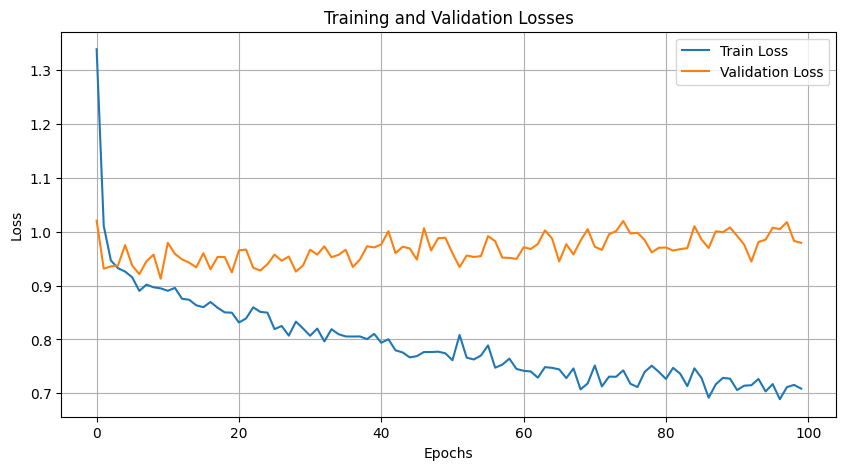


--- Classification Report ---
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.69      0.71      0.70       136
           6       0.60      0.70      0.64       128
           7       0.67      0.50      0.57        40
           8       0.00      0.00      0.00         3

    accuracy                           0.64       320
   macro avg       0.32      0.32      0.32       320
weighted avg       0.61      0.64      0.62       320



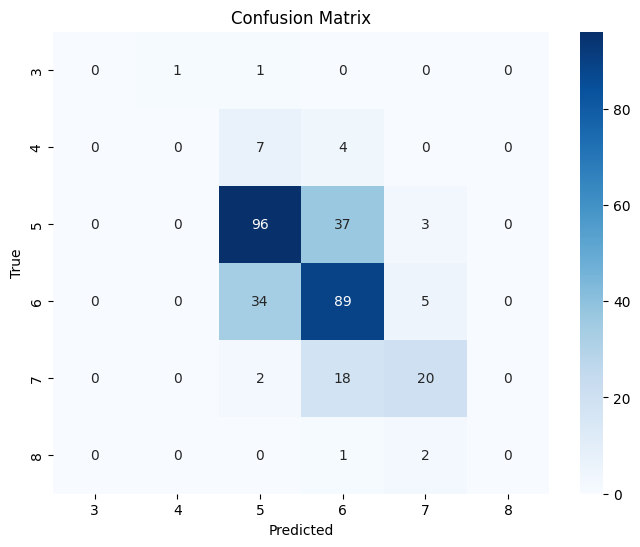

In [5]:
# Plots of losses
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Validation Loss')
plt.title('Training and Validation Losses')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Evaluate predictions
model.eval()
with torch.no_grad():
    raw_predictions = model(X_test_t)
    predictions = torch.argmax(raw_predictions, dim=1).numpy()

print("\n--- Classification Report ---")
print(classification_report(y_test, predictions, target_names=[str(c) for c in unique_qualities], zero_division=0))

# Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=unique_qualities, yticklabels=unique_qualities, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

### Step 6: Conclusions
* The standard PyTorch Multi-layer Perceptron (MLP) successfully maps physicochemical features of wines to their designated rating targets.
* Multi-class classification of subjective classes (like wine ratings) is naturally challenging due to class imbalances (mostly ratings 5 and 6, with very few extremely good or bad wines).
* Implementing dropout and batch normalization helped stabilize training and prevent rapid overfitting.